# Diferenciální evoluce


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

def sphere(x):
    return np.sum(x ** 2)

def rosenbrock(x):
    return np.sum(100.0 * (x[1:] - x[:-1] ** 2) ** 2 + (x[:-1] - 1.0) ** 2)

def schwefel(x):
    return 418.9829 * len(x) - np.sum(x * np.sin(np.sqrt(np.abs(x))))

def select_distinct(pop_size, i, count):
    indices = np.random.choice(pop_size - 1, count, replace=False)
    return indices + (indices >= i)

def mutation_rand_1(population, i, best_idx, F):
    r1, r2, r3 = select_distinct(len(population), i, 3)
    return population[r1] + F * (population[r2] - population[r3])

def mutation_best_1(population, i, best_idx, F):
    r1, r2 = select_distinct(len(population), i, 2)
    return population[best_idx] + F * (population[r1] - population[r2])

def crossover_binomial(target, mutant, CR):
    dim = len(target)
    mask = np.random.rand(dim) <= CR
    mask[np.random.randint(dim)] = True
    return np.where(mask, mutant, target)
    

In [2]:
def run_differential_evolution(cost_fn, dim, lb, ub, strategy, max_evals=10000, pop_size=50,
                               F=0.5, CR=0.8, tau1=0.1, tau2=0.1):
    mutation = mutation_best_1 if strategy == "best/1" else mutation_rand_1
    adaptive = strategy == "jde"

    population = np.random.uniform(lb, ub, (pop_size, dim))
    costs = np.array([cost_fn(ind) for ind in population])
    eval_count = pop_size
    F_values = np.full(pop_size, F)
    CR_values = np.full(pop_size, CR)

    best_so_far = costs.min()
    convergence = [best_so_far] * eval_count

    while eval_count < max_evals:
        best_idx = np.argmin(costs)
        new_population = population.copy()
        new_costs = costs.copy()
        new_F_values = F_values.copy()
        new_CR_values = CR_values.copy()

        for i in range(pop_size):
            if eval_count >= max_evals:
                break

            F_i, CR_i = F_values[i], CR_values[i]
            if adaptive:
                if np.random.rand() < tau1:
                    F_i = np.random.uniform(0.1, 0.9)
                if np.random.rand() < tau2:
                    CR_i = np.random.uniform(0.0, 1.0)

            mutant = np.clip(mutation(population, i, best_idx, F_i), lb, ub)
            trial = crossover_binomial(population[i], mutant, CR_i)
            trial_cost = cost_fn(trial)
            eval_count += 1

            if trial_cost <= costs[i]:
                new_population[i] = trial
                new_costs[i] = trial_cost
                new_F_values[i] = F_i
                new_CR_values[i] = CR_i
            best_so_far = min(best_so_far, trial_cost)
            convergence.append(best_so_far)

        population, costs = new_population, new_costs
        F_values, CR_values = new_F_values, new_CR_values

    return convergence, best_so_far
    

## Ukázka jednoho kroku DE podle schématu


In [3]:
dim = 6
pop_size = 7
F = 0.8
CR = 0.5
lb, ub = 0.0, 80.0

population = np.random.uniform(lb, ub, (pop_size, dim))
costs = np.array([sphere(ind) for ind in population])

i = 1
r1, r2, r3 = select_distinct(pop_size, i, 3)
difference = population[r2] - population[r3]
weighted = F * difference
mutant = population[r1] + weighted
trial = crossover_binomial(population[i], mutant, CR)
trial_cost = sphere(trial)

step = pd.DataFrame({
    "Aktivní x_i": population[i],
    "x_r1": population[r1],
    "x_r2": population[r2],
    "x_r3": population[r3],
    "Diferenční vektor": difference,
    "Váhovaný vektor": weighted,
    "Šumový vektor v_i": mutant,
    "Zkušební vektor u_i": trial
}, index=[f"Parametr {j + 1}" for j in range(dim)])
step.loc["Cost value"] = [costs[i], costs[r1], costs[r2], costs[r3], np.nan, np.nan, sphere(mutant), trial_cost]

print(f"Aktivní jedinec: {i + 1}, náhodní jedinci: r1={r1 + 1}, r2={r2 + 1}, r3={r3 + 1}")
print(f"Parametry zkušebního vektoru převzaté ze šumového vektoru: {[j + 1 for j in range(dim) if trial[j] != population[i][j]]}")
print(f"Selekce: {'zkušební vektor postupuje' if trial_cost <= costs[i] else 'aktivní jedinec zůstává'} ({costs[i]:.2f} vs. {trial_cost:.2f})")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
display(step)


Aktivní jedinec: 2, náhodní jedinci: r1=6, r2=7, r3=3
Parametry zkušebního vektoru převzaté ze šumového vektoru: [2, 3, 4, 5]
Selekce: aktivní jedinec zůstává (16367.93 vs. 20306.76)


,Aktivní x_i,x_r1,x_r2,x_r3,Diferenční vektor,Váhovaný vektor,Šumový vektor v_i,Zkušební vektor u_i
Parametr 1,4.646689,48.603588,24.369102,66.595411,-42.226310,-33.781048,14.822540,4.646689
Parametr 2,69.294092,13.641930,7.813769,16.987129,-9.173360,-7.338688,6.303242,6.303242
Parametr 3,48.089201,5.204127,54.738642,14.545997,40.192645,32.154116,37.358243,37.358243
Parametr 4,56.645806,75.910843,35.212199,14.672361,20.539839,16.431871,92.342714,92.342714
Parametr 5,1.646760,77.250563,9.763059,24.339379,-14.576321,-11.661057,65.589506,65.589506
Parametr 6,77.592788,64.671788,39.614153,41.980515,-2.366362,-1.893089,62.778698,77.592788
Cost value,16367.934061,18488.039630,6555.724452,7505.144551,NaN,NaN,18425.402017,20306.761827


## Konvergence variant DE na testovacích funkcích


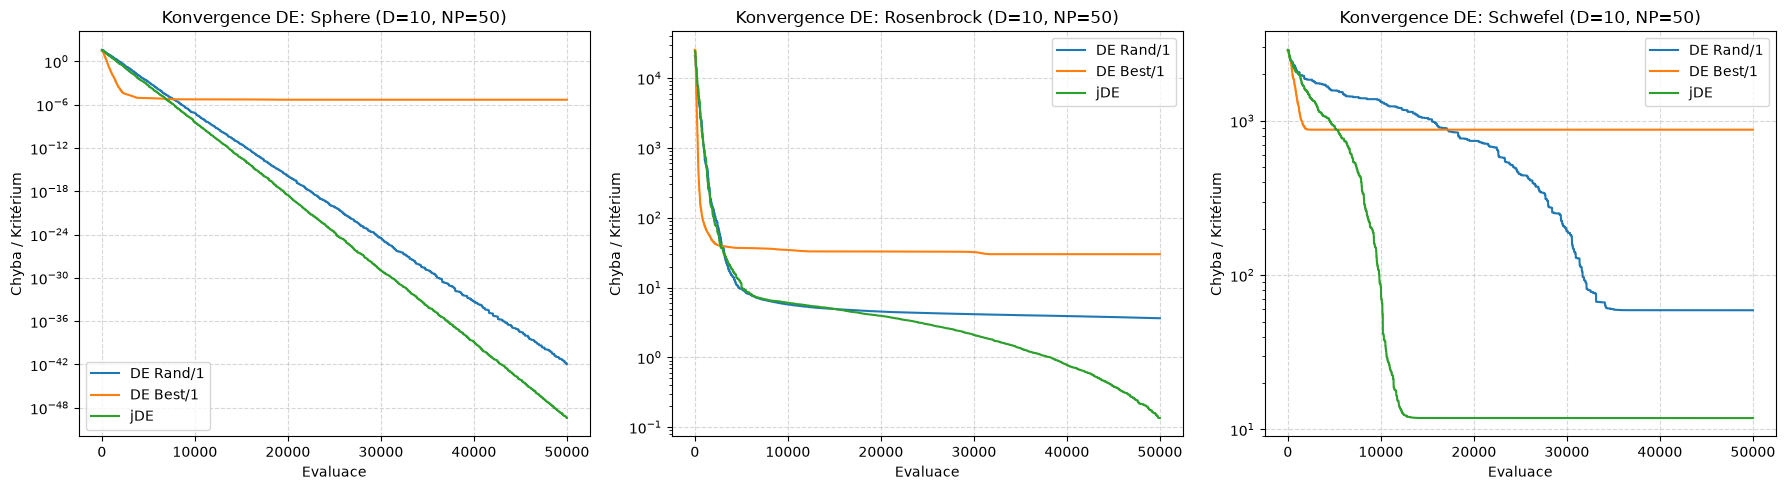

,Funkce,Varianta,Nejlepší,Nejhorší,Průměr,Medián,Směr. odchylka
0,Sphere,DE Rand/1,3.110579e-44,8.023868e-42,1.112734e-42,2.473659e-43,2.330185e-42
1,Sphere,DE Best/1,1.250659e-29,4.310336e-05,4.818184e-06,1.146062e-11,1.285116e-05
2,Sphere,jDE,1.267269e-51,2.227062e-49,3.718410e-50,1.168161e-50,6.334458e-50
3,Rosenbrock,DE Rand/1,1.851094e+00,4.744666e+00,3.630687e+00,3.551134e+00,9.385602e-01
4,Rosenbrock,DE Best/1,1.776441e-01,1.768893e+02,3.004621e+01,7.762662e+00,5.263056e+01
5,Rosenbrock,jDE,4.775996e-05,4.887855e-01,1.347570e-01,3.012100e-02,1.705393e-01
6,Schwefel,DE Rand/1,1.272757e-04,2.368768e+02,5.921929e+01,1.272757e-04,7.945085e+01
7,Schwefel,DE Best/1,5.329835e+02,1.406074e+03,8.766120e+02,8.510906e+02,2.853261e+02
8,Schwefel,jDE,1.272757e-04,1.184385e+02,1.184396e+01,1.272757e-04,3.553150e+01


In [4]:
dim = 10
max_evals = 50000
num_runs = 10
pop_size = 50
problems = {
    "Sphere": (sphere, -5.12, 5.12),
    "Rosenbrock": (rosenbrock, -5.0, 5.0),
    "Schwefel": (schwefel, -500.0, 500.0)
}
variants = {
    "DE Rand/1": {"strategy": "rand/1", "F": 0.5, "CR": 0.8},
    "DE Best/1": {"strategy": "best/1", "F": 0.5, "CR": 0.8},
    "jDE": {"strategy": "jde", "F": 0.5, "CR": 0.9, "tau1": 0.1, "tau2": 0.1}
}

fig, axes = plt.subplots(1, len(problems), figsize=(18, 5))
stats_records = []

for p_idx, (p_name, (p_fn, lb, ub)) in enumerate(problems.items()):
    ax = axes[p_idx]

    for v_name, params in variants.items():
        runs_convergence = []
        runs_scores = []
        for _ in range(num_runs):
            conv, best_val = run_differential_evolution(
                cost_fn=p_fn, dim=dim, lb=lb, ub=ub, max_evals=max_evals, pop_size=pop_size, **params
            )
            runs_convergence.append(conv)
            runs_scores.append(best_val)

        ax.plot(np.mean(runs_convergence, axis=0), label=v_name)

        stats_records.append({
            "Funkce": p_name,
            "Varianta": v_name,
            "Nejlepší": np.min(runs_scores),
            "Nejhorší": np.max(runs_scores),
            "Průměr": np.mean(runs_scores),
            "Medián": np.median(runs_scores),
            "Směr. odchylka": np.std(runs_scores)
        })

    ax.set_title(f"Konvergence DE: {p_name} (D={dim}, NP={pop_size})")
    ax.set_xlabel("Evaluace")
    ax.set_ylabel("Chyba / Kritérium")
    ax.set_yscale("log")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

df_stats = pd.DataFrame(stats_records)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
display(df_stats)


## Závěr

V rámci úlohy jsem implementoval diferenciální evoluci ve třech variantách: Rand/1, Best/1 a adaptivní jDE. Všechny používají binomické křížení a selekci, kdy do další generace postoupí lepší z dvojice rodič a potomek. Testování proběhlo na funkcích Sphere, Rosenbrock a Schwefel (D=10) při limitu 50 000 evaluací, velikosti populace $NP = 50$ a 10 nezávislých bězích.

Z naměřených konvergenčních křivek a statistických ukazatelů lze vyvodit:

* **Ukázka jednoho kroku:**
  * Vytvoření zkušebního vektoru odpovídá schématu ($NP = 7$, $F = 0{,}8$, $CR = 0{,}5$): diferenční vektor, vynásobení konstantou $F$, přičtení k náhodnému jedinci a křížení s aspoň jedním parametrem ze šumového vektoru.
  * V ukázce zkušební vektor nebyl lepší než aktivní jedinec, a ten proto zůstal v populaci.

* **DE Rand/1 ($F = 0{,}5$, $CR = 0{,}8$):**
  * Konverguje pomalu, ale spolehlivě. Na Sphere dosáhl velmi přesného řešení a na Rosenbrocku se výsledky mezi běhy příliš nelišily.
  * Na Schwefelu našel optimum jen v části běhů, ostatní uvázly v lokálním minimu.

* **DE Best/1 ($F = 0{,}5$, $CR = 0{,}8$):**
  * Zpočátku konverguje nejrychleji, protože všechna nová řešení vznikají kolem nejlepšího jedince. Populace tak ale rychle ztrácí diverzitu a konvergence se zastaví.
  * Výsledky mezi běhy se hodně liší a na Schwefelu s mnoha lokálními minimy algoritmus selhal ve všech bězích.

* **jDE ($\tau_1 = \tau_2 = 0{,}1$, počáteční $F = 0{,}5$ a $CR = 0{,}9$):**
  * Dosáhl nejlepšího průměrného výsledku na všech třech funkcích, na Sphere i Rosenbrocku výrazně lepšího než Rand/1. Na Schwefelu našel optimum v 9 bězích z 10.
  * Hodnoty $F$ a $CR$ si algoritmus upravuje sám, takže je není nutné ladit pro každou funkci zvlášť. Pevně zůstávají jen pravděpodobnosti změny $\tau$ a rozsahy $F \in [0{,}1;\ 0{,}9]$ a $CR \in [0;\ 1]$.

* **Celkové srovnání:**
  * Rand/1 je stabilní, ale pomalejší, Best/1 je rychlý, ale snadno uvázne v lokálním minimu.
  * Nejlepší kompromis mezi rychlostí a spolehlivostí poskytla varianta jDE.
  